**PROJECT TITLE**

EMPLOYEE ATTRITION PREDICTION

**PROBLEM STATEMENT**

Employee turnover (attrition) imposes heavy financial and operational costs on organizations ranging from recruitment and training overheads to lost productivity and project delays. High attrition rates can also negatively impact company morale and team cohesion. Predicting which employees are most likely to leave enables Human Resources and leadership teams to proactively implement targeted retention strategies, improve workplace satisfaction, and optimize talent management.


**PROPOSED SOLUTION**

This project proposes the use of machine learning algorithms to predict employee attrition based on employee demographics, job-related characteristics, and workplace factors. The dataset will undergo preprocessing and feature engineering, including categorical encoding and feature scaling. Exploratory data analysis will be performed to identify significant trends and relationships within the data. Multiple classification models will be trained and evaluated using metrics such as Accuracy, Precision, Recall, and F1-Score. The best-performing model will be selected to assist organizations in proactively identifying employees at risk of leaving and implementing effective retention strategies.


**DATASET DESCRIPTION**

This dataset contains information about employees within an organization. It includes employee demographics, job-related characteristics, workplace conditions, and employee attrition information. The dataset is used to build a machine learning model that predicts employee attrition and identifies the factors that influence employee turnover.
| Column                   | Description                                                                        |
| ------------------------ | ---------------------------------------------------------------------------------- |
| Employee ID              | Unique identifier assigned to each employee.                                       |
| Age                      | Age of the employee in years.                                                      |
| Gender                   | Employee's gender (Male or Female).                                                |
| Years at Company         | Number of years the employee has worked at the organization.                       |
| Job Role                 | Employee's position or role within the company.                                    |
| Monthly Income           | Monthly salary earned by the employee.                                             |
| Work-Life Balance        | Employee's rating of work-life balance.                                            |
| Job Satisfaction         | Employee's level of satisfaction with their job.                                   |
| Performance Rating       | Employee's performance evaluation score.                                           |
| Number of Promotions     | Total number of promotions received during employment.                             |
| Overtime                 | Indicates whether the employee works overtime (Yes/No).                            |
| Distance from Home       | Distance between the employee's residence and workplace.                           |
| Education Level          | Highest educational qualification attained by the employee.                        |
| Marital Status           | Employee's marital status (e.g., Single, Married, Divorced).                       |
| Number of Dependents     | Number of dependents supported by the employee.                                    |
| Job Level                | Employee's level or rank within the organization.                                  |
| Company Size             | Size category of the organization.                                                 |
| Company Tenure           | Total duration of the employee's association with the company.                     |
| Remote Work              | Indicates whether the employee works remotely (Yes/No).                            |
| Leadership Opportunities | Availability of leadership and career advancement opportunities.                   |
| Innovation Opportunities | Availability of opportunities to contribute innovative ideas and initiatives.      |
| Company Reputation       | Employee's perception of the organization's reputation.                            |
| Employee Recognition     | Indicates the level of recognition and appreciation received by the employee.      |
| Attrition                | Target variable indicating whether the employee left the organization or remained. |

**IMPORT LIBRARIES**



In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
import joblib

**LOAD DATASET**

In [33]:
df=pd.read_csv("Attrition.csv")
df

,Employee ID,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,...,Number of Dependents,Job Level,Company Size,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Attrition
0,52685,36,Male,13,Healthcare,8029,Excellent,High,Average,1,...,1,Mid,Large,22,No,No,No,Poor,Medium,Stayed
1,30585,35,Male,7,Education,4563,Good,High,Average,1,...,4,Entry,Medium,27,No,No,No,Good,High,Left
2,54656,50,Male,7,Education,5583,Fair,High,Average,3,...,2,Senior,Medium,76,No,No,Yes,Good,Low,Stayed
3,33442,58,Male,44,Media,5525,Fair,Very High,High,0,...,4,Entry,Medium,96,No,No,No,Poor,Low,Left
4,15667,39,Male,24,Education,4604,Good,High,Average,0,...,6,Mid,Large,45,Yes,No,No,Good,High,Stayed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14895,16243,56,Female,42,Healthcare,7830,Poor,Medium,Average,0,...,0,Senior,Medium,60,No,No,No,Poor,Medium,Stayed
14896,47175,30,Female,15,Education,3856,Good,Medium,Average,2,...,0,Entry,Medium,20,No,No,No,Good,Medium,Left
14897,12409,52,Male,5,Education,5654,Good,Very High,Below Average,0,...,4,Mid,Small,7,No,No,No,Good,High,Left
14898,9554,18,Male,4,Education,5276,Fair,High,Average,0,...,3,Mid,Large,5,No,No,No,Poor,High,Stayed


**EDA**

DATASET INSPECTION

In [34]:
df.shape

(14900, 24)

In [35]:
df.dtypes

Employee ID                  int64
Age                          int64
Gender                      object
Years at Company             int64
Job Role                    object
Monthly Income               int64
Work-Life Balance           object
Job Satisfaction            object
Performance Rating          object
Number of Promotions         int64
Overtime                    object
Distance from Home           int64
Education Level             object
Marital Status              object
Number of Dependents         int64
Job Level                   object
Company Size                object
Company Tenure               int64
Remote Work                 object
Leadership Opportunities    object
Innovation Opportunities    object
Company Reputation          object
Employee Recognition        object
Attrition                   object
dtype: object

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14900 entries, 0 to 14899
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Employee ID               14900 non-null  int64 
 1   Age                       14900 non-null  int64 
 2   Gender                    14900 non-null  object
 3   Years at Company          14900 non-null  int64 
 4   Job Role                  14900 non-null  object
 5   Monthly Income            14900 non-null  int64 
 6   Work-Life Balance         14900 non-null  object
 7   Job Satisfaction          14900 non-null  object
 8   Performance Rating        14900 non-null  object
 9   Number of Promotions      14900 non-null  int64 
 10  Overtime                  14900 non-null  object
 11  Distance from Home        14900 non-null  int64 
 12  Education Level           14900 non-null  object
 13  Marital Status            14900 non-null  object
 14  Number of Dependents  

In [37]:
df.duplicated().sum()

np.int64(0)

In [40]:
df.isnull().sum()

Employee ID                 0
Age                         0
Gender                      0
Years at Company            0
Job Role                    0
Monthly Income              0
Work-Life Balance           0
Job Satisfaction            0
Performance Rating          0
Number of Promotions        0
Overtime                    0
Distance from Home          0
Education Level             0
Marital Status              0
Number of Dependents        0
Job Level                   0
Company Size                0
Company Tenure              0
Remote Work                 0
Leadership Opportunities    0
Innovation Opportunities    0
Company Reputation          0
Employee Recognition        0
Attrition                   0
dtype: int64

In [41]:
df.columns

Index(['Employee ID', 'Age', 'Gender', 'Years at Company', 'Job Role',
       'Monthly Income', 'Work-Life Balance', 'Job Satisfaction',
       'Performance Rating', 'Number of Promotions', 'Overtime',
       'Distance from Home', 'Education Level', 'Marital Status',
       'Number of Dependents', 'Job Level', 'Company Size', 'Company Tenure',
       'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities',
       'Company Reputation', 'Employee Recognition', 'Attrition'],
      dtype='object')

In [42]:
df.select_dtypes(include=['number']).columns.tolist()

['Employee ID',
 'Age',
 'Years at Company',
 'Monthly Income',
 'Number of Promotions',
 'Distance from Home',
 'Number of Dependents',
 'Company Tenure']

In [43]:
df.select_dtypes(include=['object']).columns.tolist()

['Gender',
 'Job Role',
 'Work-Life Balance',
 'Job Satisfaction',
 'Performance Rating',
 'Overtime',
 'Education Level',
 'Marital Status',
 'Job Level',
 'Company Size',
 'Remote Work',
 'Leadership Opportunities',
 'Innovation Opportunities',
 'Company Reputation',
 'Employee Recognition',
 'Attrition']

In [44]:
for col in df.columns:
    print(f"\n{"="*40}")
    print(f"COLUMN: {col}")
    print(f"{"="*40}")
    print(df[col].value_counts(dropna=False))


COLUMN: Employee ID
Employee ID
52685    1
49032    1
31573    1
33241    1
22611    1
        ..
55645    1
69289    1
24862    1
10980    1
73042    1
Name: count, Length: 14900, dtype: int64

COLUMN: Age
Age
32    390
53    386
40    386
33    385
56    384
19    379
45    379
35    378
34    374
43    373
29    372
36    370
27    369
30    368
21    368
55    368
57    367
38    364
31    362
46    358
22    358
18    356
51    356
24    352
37    350
58    345
20    344
39    343
54    343
52    342
42    341
26    340
28    340
23    332
41    330
25    326
50    326
44    326
59    325
49    317
48    315
47    313
Name: count, dtype: int64

COLUMN: Gender
Gender
Male      8087
Female    6813
Name: count, dtype: int64

COLUMN: Years at Company
Years at Company
1     635
5     628
8     612
6     608
10    607
4     601
7     597
3     595
2     586
11    567
9     565
12    552
13    499
15    444
14    439
17    424
16    419
18    406
20    364
19    351
21    334
23    334


DATA VISUALIZATION

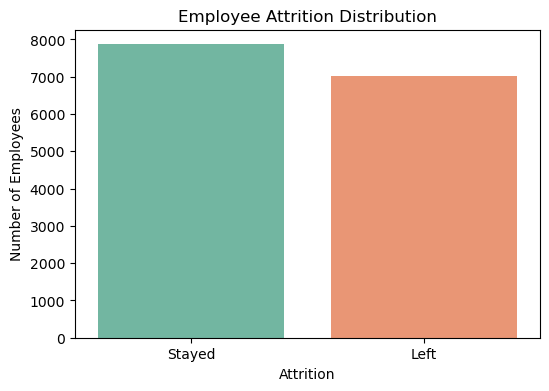

In [45]:
plt.figure(figsize=(6,4))
sns.countplot(x='Attrition', data=df, palette='Set2', hue='Attrition')
plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.show()

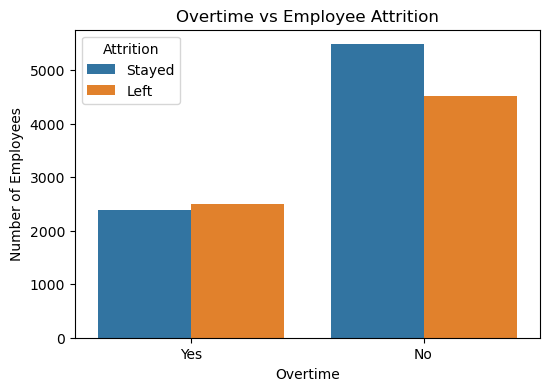

In [46]:
plt.figure(figsize=(6,4))
sns.countplot(x='Overtime', hue='Attrition', data=df)
plt.title('Overtime vs Employee Attrition')
plt.xlabel('Overtime')
plt.ylabel('Number of Employees')
plt.show()

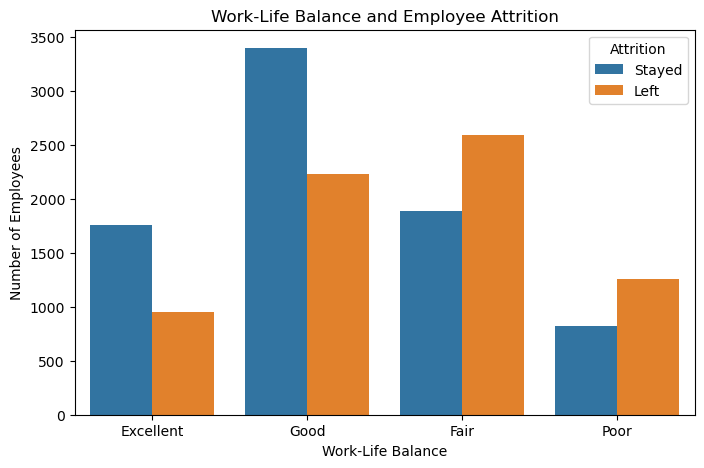

In [47]:
plt.figure(figsize=(8,5))
sns.countplot(x='Work-Life Balance', hue='Attrition', data=df)
plt.title('Work-Life Balance and Employee Attrition')
plt.xlabel('Work-Life Balance')
plt.ylabel('Number of Employees')
plt.show()

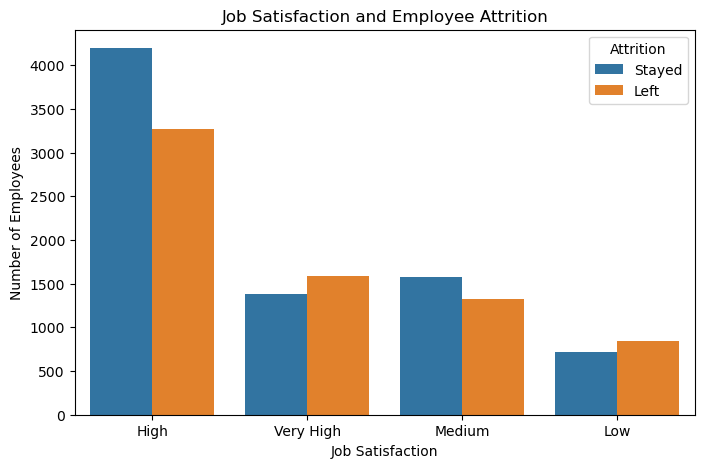

In [48]:
plt.figure(figsize=(8,5))
sns.countplot(x='Job Satisfaction', hue='Attrition', data=df)
plt.title('Job Satisfaction and Employee Attrition')
plt.xlabel('Job Satisfaction')
plt.ylabel('Number of Employees')
plt.show()

**FEATURE ENGINEERING**

In [49]:
encoders = {}

categorical_columns = ['Attrition', 'Overtime', 'Job Role']

for column in df:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])
    encoders[column] = label_encoder

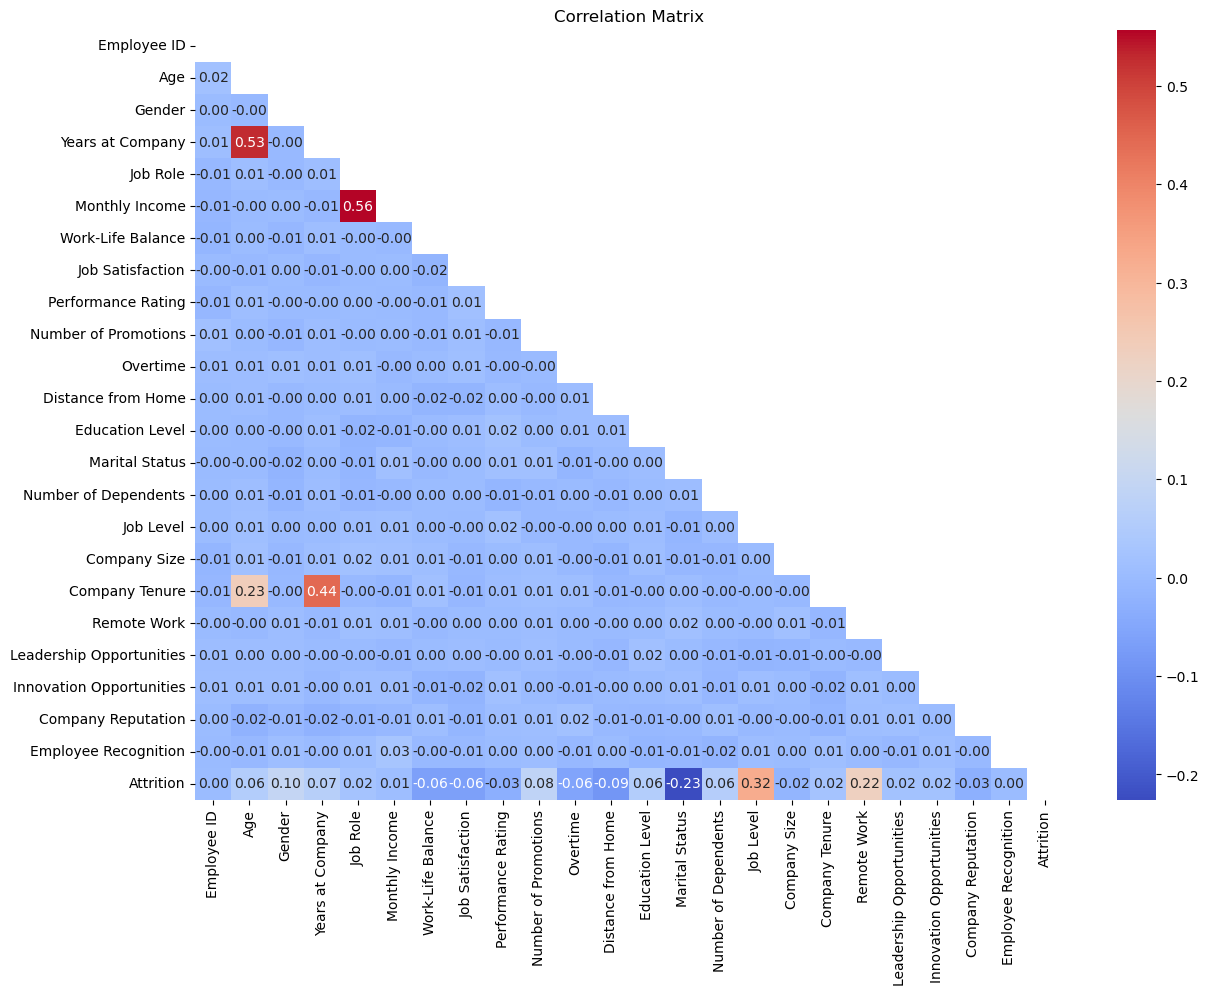

In [50]:
plt.figure(figsize = (14, 10))
cut_upper = np.triu(df.corr())
sns.heatmap(df.corr(), annot=True, cmap = "coolwarm", fmt = ".2f", mask = cut_upper)
plt.title("Correlation Matrix")
plt.show()

In [51]:
df_ml= df.drop('Employee ID', axis=1)

In [52]:
X = df_ml.drop('Attrition', axis=1)
y = df_ml['Attrition']

In [53]:
X

,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,Overtime,...,Marital Status,Number of Dependents,Job Level,Company Size,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition
0,18,1,12,2,4060,0,0,0,1,1,...,1,1,1,0,20,0,0,0,3,2
1,17,1,6,0,1058,2,0,0,1,1,...,2,4,0,1,25,0,0,0,2,0
2,32,1,6,0,1904,1,0,0,3,1,...,0,2,2,1,74,0,0,1,2,1
3,40,1,43,3,1853,1,3,2,0,1,...,2,4,0,1,94,0,0,0,3,1
4,21,1,23,0,1093,2,0,0,0,1,...,1,6,1,0,43,1,0,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14895,38,0,41,2,3876,3,2,0,0,1,...,2,0,2,1,58,0,0,0,3,2
14896,12,0,14,0,515,2,2,0,2,1,...,1,0,0,1,18,0,0,0,2,2
14897,34,1,4,0,1968,2,3,1,0,0,...,1,4,1,2,5,0,0,0,2,0
14898,0,1,3,0,1635,1,0,0,0,0,...,0,3,1,0,3,0,0,0,3,0


**SPLIT DATASET**

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

**TRAIN MODEL**

In [55]:
rf_model = RandomForestClassifier(random_state=42)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)

# Evaluation
print("========== Random Forest ==========")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall Score:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report")
print(classification_report(y_test, rf_pred))

========== Random Forest ==========
Accuracy: 0.7295302013422819
Precision: 0.754055807916937
Recall Score: 0.7312775330396476
F1 Score: 0.7424920127795527

Confusion Matrix
[[1012  379]
 [ 427 1162]]

Classification Report
              precision    recall  f1-score   support

           0       0.70      0.73      0.72      1391
           1       0.75      0.73      0.74      1589

    accuracy                           0.73      2980
   macro avg       0.73      0.73      0.73      2980
weighted avg       0.73      0.73      0.73      2980



In [56]:
lr_model = LogisticRegression(max_iter=10000, random_state=42)

# Train model
lr_model.fit(X_train, y_train)

# Predictions
lr_pred = lr_model.predict(X_test)

# Evaluation
print("========== Logistic Regression ==========")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall Score:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, lr_pred))

print("\nClassification Report")
print(classification_report(y_test, lr_pred))


========== Logistic Regression ==========
Accuracy: 0.7104026845637584
Precision: 0.7329910141206675
Recall Score: 0.7186910006293267
F1 Score: 0.7257705751509373

Confusion Matrix
[[ 975  416]
 [ 447 1142]]

Classification Report
              precision    recall  f1-score   support

           0       0.69      0.70      0.69      1391
           1       0.73      0.72      0.73      1589

    accuracy                           0.71      2980
   macro avg       0.71      0.71      0.71      2980
weighted avg       0.71      0.71      0.71      2980



In [57]:
xgb_model = XGBClassifier(random_state=42)

# Train model
xgb_model.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test)

# Evaluation
print("========== XGBoost ==========")
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall Score:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, xgb_pred))

print("\nClassification Report")
print(classification_report(y_test, xgb_pred))

========== XGBoost ==========
Accuracy: 0.7355704697986577
Precision: 0.7555839183152521
Recall Score: 0.7451227186910007
F1 Score: 0.7503168567807351

Confusion Matrix
[[1008  383]
 [ 405 1184]]

Classification Report
              precision    recall  f1-score   support

           0       0.71      0.72      0.72      1391
           1       0.76      0.75      0.75      1589

    accuracy                           0.74      2980
   macro avg       0.73      0.73      0.73      2980
weighted avg       0.74      0.74      0.74      2980



In [64]:
# Setting hyperparameter tuning grids
param_grids = {
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100], # Inverse Regularization Strength which controls how model penalizes large coefficients to prevent overfitting.
        'penalty': ['l2'] # L2 is Ridge regularization which is a Regularization Type that specifies the mathematical method used to penalize complex models
    },
    'Random Forest': {
        'n_estimators': [100, 200, 300],    # Number of trees
        'max_depth': [10, 20, None],        # Tree Depth limit
        'min_samples_split': [2, 5, 10],    # Node splitting threshold 
        'criterion': ['gini', 'entropy']    # Quality of split. gini calculates the probability of a misclassification, while entropy uses information gain
    },
    'Gradient Boosting': {
        'n_estimators': [100, 200, 300], 
        'learning_rate': [0.01, 0.05, 0.1, 0.2], # the speed at the which the model learns. Low is good for better understanding
        'max_depth': [3, 4, 5], 
        'subsample': [0.8, 1.0] # Row Subsampling. 0.8 means each tree only looks at 80% of the data
    },
    'XGBoost':{
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 5, 7],
        'subsample': [0.8, 1.0]
    }
        
}


# Setting the models
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=10000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
    
}

tuned_predictions = {}
best_estimators = {}

# Run Grid Search for each model. This is where the grid looks for the best combination in the models to find perfect match to retrain the models
print("Tuning models: This may take a few minutes...")
for name, model in base_models.items():
    print(f"-> Tuning {name}...")
    
    grid_search = GridSearchCV(
        estimator=model, 
        param_grid=param_grids[name], 
        cv=5, 
        scoring='accuracy', 
        n_jobs=-1
    )
    
    # Train using the correct scaling splits
    if name == 'Logistic Regression':
        grid_search.fit(X_train, y_train)
        tuned_predictions[name] = grid_search.predict(X_test)
    else:
        grid_search.fit(X_train, y_train)
        tuned_predictions[name] = grid_search.predict(X_test)
        
    # Save the optimized model objects for deep analysis later
    best_estimators[name] = grid_search.best_estimator_

# Generate the summary table
tuned_metrics_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": f"{accuracy_score(y_test, y_pred):.4f}",
        "Precision": f"{precision_score(y_test, y_pred):.4f}",
        "Recall Score": f"{recall_score(y_test, y_pred):.4f}",
        "F1-Score": f"{f1_score(y_test, y_pred):.4f}"
    }
    for name, y_pred in tuned_predictions.items()
])

print("\n" + "=" * 65)
print("          TUNED MODEL EVALUATION METRICS COMPARISON            ")
print("=" * 65)
print(tuned_metrics_df.to_string(index=False))
print("=" * 65)

# Extract and show best parameters for your top-performing tree model
print("\n--- Best Parameters Found ---")
print(f"Random Forest: {best_estimators['Random Forest'].get_params()}")
print(f"Gradient Boosting: {best_estimators['Gradient Boosting'].get_params()}")
print(f"XGBoost: {best_estimators['XGBoost'].get_params()}")

Tuning models: This may take a few minutes...
-> Tuning Logistic Regression...
-> Tuning Random Forest...
-> Tuning Gradient Boosting...
-> Tuning XGBoost...

          TUNED MODEL EVALUATION METRICS COMPARISON            
              Model Accuracy Precision Recall Score F1-Score
Logistic Regression   0.7104    0.7330       0.7187   0.7258
      Random Forest   0.7366    0.7610       0.7376   0.7491
  Gradient Boosting   0.7430    0.7674       0.7432   0.7551
            XGBoost   0.7403    0.7631       0.7439   0.7533

--- Best Parameters Found ---
Random Forest: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Gradient Boo

In [ ]:
y_signal = df['Attrition'].map({'Yes': 1, 'No': 0}) if df['Attrition'].dtype == 'O' else df['Attrition']

# Select numeric features and one-hot encode text features for clean evaluation
X_signal = pd.get_dummies(df.drop(columns=['Attrition']), drop_first=True)

# Evaluate every single column individually
column_scores = {}
baseline_model = DecisionTreeClassifier(max_depth=3, random_state=42)

for col in X_signal.columns:
    single_col_data = X_signal[[col]]
    scores = cross_val_score(baseline_model, single_col_data, y_signal, cv=3, scoring='accuracy')
    column_scores[col] = scores.mean()

# Dataframe Ranking
signal_df = pd.DataFrame(list(column_scores.items()), columns=['Column Name', 'Standalone Accuracy'])
signal_df = signal_df.sort_values(by='Standalone Accuracy', ascending=False).reset_index(drop=True)

print("=" * 55)
print("       INDIVIDUAL COLUMN SIGNAL STRENGTH RANKING       ")
print("=" * 55)
print(signal_df.to_string())
print("=" * 55)

**SAVE MODEL**

In [67]:
joblib.dump(best_estimators['Gradient Boosting'],'gradient_boosting_employee_attrition.pkl')
print("Model saved successfully.")

Model saved successfully.


**CONCLUSION**

This project successfully developed and evaluated machine learning models to predict employee attrition using HR data. The dataset was preprocessed through data cleaning, feature engineering, and encoding before training multiple classification models, including Logistic Regression, Random Forest, Gradient Boosting, and XGBoost. After evaluating their performance, Gradient Boosting produced the best overall results and was selected as the most suitable model for this dataset. The findings demonstrate how machine learning can be used to identify employees who may be at risk of leaving, enabling organizations to make proactive, data-driven decisions that improve employee retention, workforce planning, and overall organizational performance.